# Review

Well, Class We've arrived:

![Screenshot%202020-02-23%2018.44.43.png](https://github.com/BlohmLab/NSCI801-QuantNeuro/blob/master/Figures/lastlec.png?raw=1)

# Image processing

Scikit-image is a Python package dedicated to image processing, and using natively NumPy arrays as image objects. This lecture describes how to use scikit-image on various image processing tasks, and links it with other scientific Python modules such as NumPy and SciPy

### Why do we care?

Neuroscience generates enormous amounts of image data — MRI and fMRI scans, histology slides, fluorescence microscopy, calcium imaging, electron microscopy, etc.

Digital image processing gives us the tools to go from a raw image to a measurement, a segmentation, a classification, or a comparison. Without it, a lot of modern neuroscience simply wouldn't be possible.

### Some digital image processing methods:

**Classification** - Assigning pixels, regions, or whole images to discrete and predefined categories.

**Feature extraction** - Identifying and quantifying meaningful structures or measurements within an image, reducing it from raw pixel data to something interpretable.

**Multi-scale signal analysis** - Analyzing signals at different spatial or temporal scales. Ex. examining an image at multiple levels of resolution simultaneously, capturing both fine detail and broad structure.

**Pattern recognition** - Detecting recurring structures or arrangements within an image, often across many examples.

**Projection** - Transforming high-dimensional image data into lower-dimensional representations.

How do we display images?

The package to use is Matplotlib, and displaying 2D images is done using imshow:

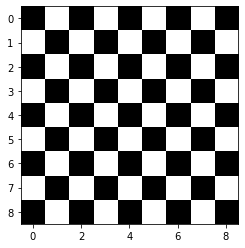

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Create a 9x9 numpy array of zeros (black)
check = np.zeros((9, 9))
# Set alternating cells to 1 (white)
# "::2" indexes every other row/column starting at 0, "1::2" indexes every other row/column starting at 1
check[::2, 1::2] = 1 
check[1::2, ::2] = 1
# Create and display plot
plt.imshow(check, cmap='gray', interpolation='nearest') 
plt.show()

We did it:

![alt text](https://github.com/BlohmLab/NSCI801-QuantNeuro/blob/master/Figures/Boom.png?raw=1)

A digital image is just a 2D array/matrix of numbers where each entry is a pixel intensity value.

# Input/output and data types 

### Reading from files: skimage.io.imread()

io.imread() is doing two things: locating a file and decoding it into a NumPy array.

Works with all data formats supported by the Python Imaging Library (or any other I/O plugin provided to imread with the plugin keyword argument). Also works with URL image paths.

Once it's in memory, it doesn't matter whether it came from a PNG, JPEG, TIFF, or URL — it's just an array of numbers.

In [13]:
# !pip install scikit-image

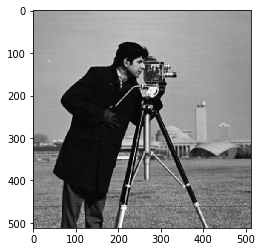

In [3]:
from skimage import io, filters
from skimage import data
import skimage as ski
import os

filename = os.path.join(ski.data_dir, 'camera.png') # points to the data directory inside scikit-image
camera = io.imread(filename) # load the image into a NumPy array
# web_file = io.imread('http://scikit-image.org/_static/img/logo.png') # from url
# local_file= io.imread('/Users/joe/Downloads/dixie.jpg') # from local file

plt.imshow(camera, cmap='gray', interpolation='nearest') # displays image as grayscale
plt.show()

Image ndarrays can be represented either by integers (signed or unsigned) or floats.

Different integer sizes are possible: 8-, 16- or 32-bytes, signed or unsigned. Careful with overflows with integer data types

In [19]:
print(camera.dtype)
print(camera.shape)

uint8
(512, 512)


A uint8 (unsigned, 8-bit) image stores each pixel as an integer between 0 and 255.

(512, 512) means the image is 512×512 pixels, each stored as a single byte.

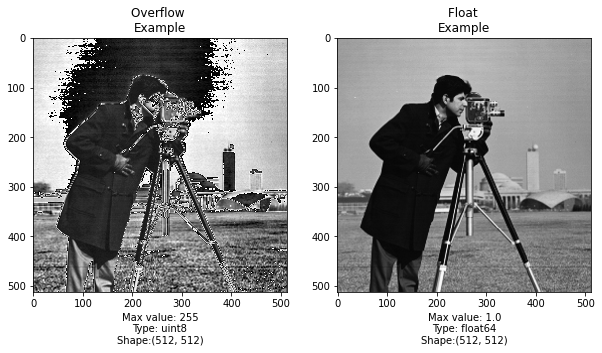

In [54]:
from skimage import img_as_float

camera = data.camera()
camera_multiplied = 3 * camera # Creates overflow
camera_float = img_as_float(camera) # Converts the array to 64-bit floating point

# Create plot
fig, ax = plt.subplots(1, 2, figsize=(10, 6))
# Overflow example
ax[0].set_title("Overflow \nExample")
ax[0].imshow(camera_multiplied, cmap='gray', interpolation='nearest')
ax[0].set_xlabel(f"Max value: {camera_multiplied.max()}\nType: {camera_multiplied.dtype}\nShape:{camera_multiplied.shape}")
# Float example
ax[1].set_title("Float \nExample")
ax[1].imshow(camera_float, cmap='gray', interpolation='nearest')
ax[1].set_xlabel(f"Max value: {camera_float.max()}\nType: {camera_float.dtype}\nShape:{camera_float.shape}")
plt.show()

### Overflow problem
When you do 3 * camera, you're multiplying a uint8 array by 3. 

Any pixel value above 85 will exceed 255, and instead of being clipped it wraps around. Ex. 256 becomes 0, 257 becomes 1, and so on.


### Solution:

Convert the array to a higher integer type (Ex. camera.astype(np.uint16)) or use **img_as_float()** which converts the array to 64-bit floating point and rescales the range from 0–255 to 0.0–1.0.

Some image processing routines need to work with float arrays, and may hence output an array with a different type and the data range from the input array.

**Note:**
The tradeoff is memory. A float64 array uses 8 bytes per pixel versus 1 byte for uint8, so for large datasets this matters. Many skimage functions will automatically convert to float internally. This is why the filters.gaussian() example below outputs a float even when given a uint8 input.

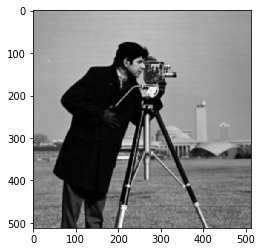

0.9857924134704021
float64
(512, 512)


In [56]:
from skimage import filters

camera_gaussian = filters.gaussian(camera, 1) # Applies Gaussian filter
plt.imshow(camera_gaussian, cmap='gray', interpolation='nearest') 
plt.show()

print(camera_gaussian.max())
print(camera_gaussian.dtype)
print(camera_gaussian.shape)

Color images are of shape (N, M, 3) or (N, M, 4). The 3 values per pixel are the R, G, B intensities and the optional 4th channel is for an alpha value which encodes transparency.

Routines converting between different colorspaces (RGB, HSV, LAB etc.) are available in skimage.color: color.rgb2hsv, color.lab2rgb, etc. Check the docstring for the expected dtype (and data range) of input images.

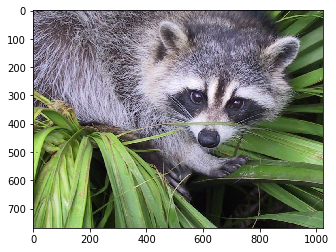

(768, 1024, 3)


In [78]:
import scipy

face = scipy.misc.face()
plt.imshow(face, interpolation='nearest') # no need for cmap because RGB values are provided
plt.show()

print(face.shape)

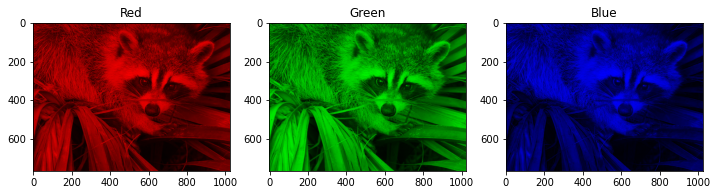

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ['Red', 'Green', 'Blue']

for i, ax in enumerate(axes):
    channel = np.zeros_like(face)
    channel[:, :, i] = face[:, :, i]
    ax.imshow(channel)
    ax.set_title(titles[i])
plt.show()

# Filters

Filtering transforms an image to make some property of it more visible, more measurable, or more suitable for the next step in analysis. Here's a brief overview of the main goals:
- Denoising
- Sharpening
- Feature/Edge Detection
- Contrast Enhancement

Filters can be linear or non-linear.

Filters can be local or non-local.

### Local Filters

The core concept of local filters is the convolution operation. You slide a small matrix called a kernel (or filter) across the image, and at each position you compute a function of the pixels under the kernel to produce the output pixel value.  


**LEFT**: Mean/averaging filter - Replaces each pixel with the local average, which smooths out noise. (Linear)

**CENTRE**: Max filter - Each pixel takes the maximum value found among its neighbours, useful for things like dilating bright structures. (Non-linear)

**RIGHT**:  Structuring element - the blue cells are the neighbours that get included in the calculation, which in this case is a diamond shape rather than the full 3×3 square.

Neighbourhood: diamond, square, disk, or more complicated structuring element.

![kernels1.png](https://github.com/BlohmLab/NSCI801-QuantNeuro/blob/master/Figures/kernels1.png?raw=1)

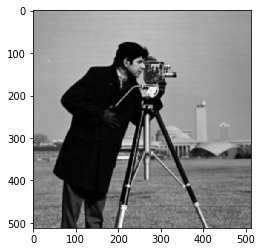

0.9857924134704021
float64
(512, 512)


In [106]:
# Gaussian Filter Example
# Uses a kernel which weights nearby pixels heavily and distant pixels lightly. Smoothing effect.
camera_gaussian = filters.gaussian(camera, 1) # Applies Gaussian filter
plt.imshow(camera_gaussian, cmap='gray', interpolation='nearest') 
plt.show()

print(camera_gaussian.max())
print(camera_gaussian.dtype)
print(camera_gaussian.shape)

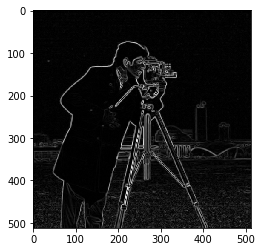

0.5915023652179584
float64
(512, 512)


In [59]:
# Sobel Filter Example
# Uses a kernel designed to compute the intensity gradient in a particular direction, which highlights edges
camera_sobel = filters.sobel(camera) 
plt.imshow(camera_sobel, cmap='gray', interpolation='nearest') 
plt.show()

print(camera_sobel.max())
print(camera_sobel.dtype)
print(camera_sobel.shape)

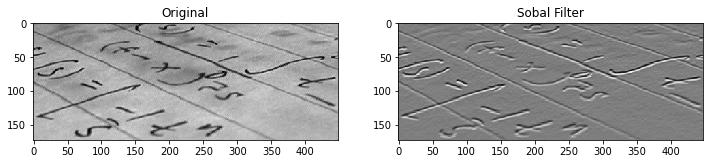

In [4]:
# The Sobel filter actually consists of two separate kernels, one detecting horizontal edges and one detecting vertical edges
# These can be applied seperately using sobel_v (vertical) or sobel_h (horizontal)
text = data.text()
sobel_text = filters.sobel_h(text)

# Create plot
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
# Original
ax[0].set_title("Original")
ax[0].imshow(text, cmap='gray', interpolation='nearest') 
# Filtered
ax[1].set_title("Sobal Filter")
ax[1].imshow(sobel_text, cmap='gray', interpolation='nearest') 
plt.show()

### Non-Local Filters

Non-local filters use a large region of the image (or all the image) to transform the value of one pixel.

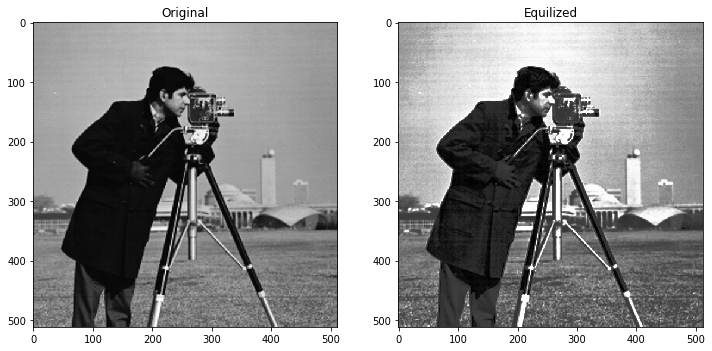

In [129]:
# Histogram equalization example
# Redistributes pixel intensities across the full available range to maximize contrast
from skimage import exposure
camera = data.camera()
camera_equalized = exposure.equalize_hist(camera)

# Create plot
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
# Original
ax[0].set_title("Original")
ax[0].imshow(camera, cmap='gray', interpolation='nearest') 
# Filtered
ax[1].set_title("Equilized")
ax[1].imshow(camera_equalized, cmap='gray', interpolation='nearest') 
plt.show()

In practice most image processing pipelines use both a non-local filtering step to correct global issues like contrast and background, followed by local filtering steps for denoising and feature detection.

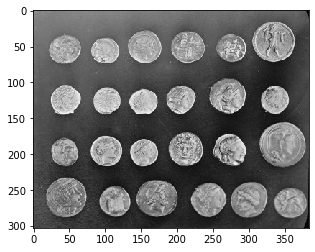

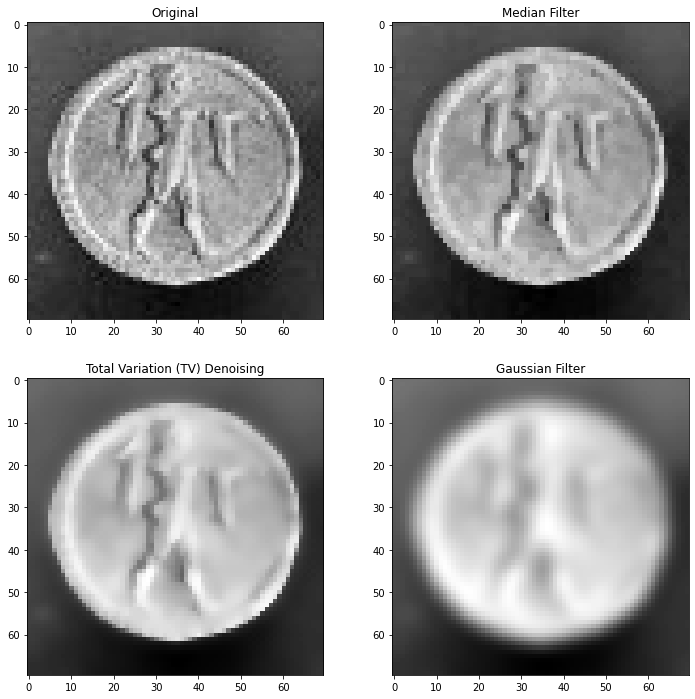

In [104]:
# Filter comparison for image denoising
from skimage.morphology import disk
from skimage import restoration

coins = data.coins()
plt.imshow(coins, cmap='gray', interpolation='nearest') 
plt.show()

coins_zoom = coins[10:80, 300:370] # slicing out a small region of interest from full image
median_coins = filters.median(coins_zoom, disk(1))
tv_coins = restoration.denoise_tv_chambolle(coins_zoom, weight=0.1)
gaussian_coins = filters.gaussian(coins_zoom, sigma=2)

# Create plot
fig, ax = plt.subplots(2, 2, figsize=(12, 12))
# Original
ax[0,0].set_title("Original")
ax[0,0].imshow(coins_zoom, cmap='gray', interpolation='nearest') 
# Median - replaces each pixel with the median value of all neighbours
ax[0,1].set_title("Median Filter")
ax[0,1].imshow(median_coins, cmap='gray', interpolation='nearest')
# TV denoising - minimizes the total variation of an image
ax[1,0].set_title("Total Variation (TV) Denoising")
ax[1,0].imshow(tv_coins, cmap='gray', interpolation='nearest') 
# Gaussian - weights nearby pixels heavily and distant pixels lightly
ax[1,1].set_title("Gaussian Filter")
ax[1,1].imshow(gaussian_coins, cmap='gray', interpolation='nearest') 
plt.show()

## Morphological Operations

Filters in this category are local and non-linear, but they are uniquely designed with shape and geometry in mind.

Probe an image with a specific shape (a structuring element), and modify this image according to how the shape locally fits or misses the image.

Morphological operations are important because they give you precise control over the shape and structure of objects in a binary or greyscale image, which is something linear filters can't do.

Powerful for tasks like:
- Cleaning up segmentation masks
- Separating touching objects
- Measuring and analyzing shape
- Enhancing or suppressing specific structures

In [145]:
# Default structuring element: 4-connectivity of a pixel
from skimage import morphology
morphology.diamond(1) # Try disk, square, star

array([[0, 1, 0],
       [1, 1, 1],
       [0, 1, 0]], dtype=uint8)

**Erosion** - minimum filter. Replace the value of a pixel by the minimal value covered by the structuring element

In [94]:
arr = np.zeros((7,7), dtype=np.uint8)
arr[1:6, 2:5] = 1
print(arr)

#Erosion removes objects smaller than the structure
print(morphology.binary_erosion(arr, morphology.diamond(1)).astype(np.uint8))
# print(morphology.binary_erosion(arr, morphology.diamond(2)).astype(np.uint8))


[[0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]]
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


**Dilation** - maximum filter. Replace the value of a pixel by the maximum value covered by the structuring element:

In [95]:
arr = np.zeros((5, 5))
arr[2, 2] = 1
print(arr)

print(morphology.binary_dilation(arr, morphology.diamond(1)).astype(np.uint8))

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 1 1 1 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]


**Opening** - erosion + dilation. Removes small objects and smoothes corners.

In [97]:
arr = np.zeros((5,5), dtype=np.int)
arr[1:4, 1:4] = 1; arr[4, 4] = 1
print(arr)

# arr2 = morphology.binary_erosion(arr, morphology.diamond(1)).astype(np.uint8)
# print(arr2)

print(morphology.binary_opening(arr, morphology.diamond(1)).astype(np.uint8))

[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 1]]
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 1 1 1 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]


## Image segmentation

Segmentation is the process of partitioning an image into meaningful regions by assigning a label to every pixel. 

Rather than treating the image as a single array of intensity values, segmentation produces a map where each pixel is identified as belonging to a particular object or class. 

The output might be binary (Ex. foreground versus background) or it might have many labels, like the coloured nucleus map later in this notebook.

Image segmentation is the attribution of different labels to different regions of the image, for example in order to extract the pixels of an object of interest.

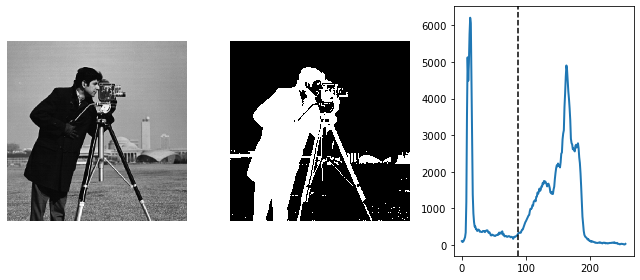

In [0]:
# Binary segmentation example: foreground + background
from skimage import data
from skimage import filters
camera = data.camera()
val = filters.threshold_otsu(camera)
mask = camera < val

import matplotlib.pyplot as plt
from skimage import data
from skimage import filters
from skimage import exposure

camera = data.camera()
val = filters.threshold_otsu(camera)

hist, bins_center = exposure.histogram(camera)

plt.figure(figsize=(9, 4))
plt.subplot(131) 
plt.imshow(camera, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.subplot(132)
plt.imshow(camera < val, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.subplot(133)
plt.plot(bins_center, hist, lw=2)
plt.axvline(val, color='k', ls='--')

plt.tight_layout()
plt.show()

So The Question is why is this helpful??

# Cell Counting



![dna](https://github.com/BlohmLab/NSCI801-QuantNeuro/blob/master/Figures/dna.jpeg?raw=true)

In [148]:
# !pip install mahotas

In [ ]:
import numpy as np
import pylab
import mahotas as mh

#read in data
dna = mh.imread('Figures/dna.jpeg')
dna.shape
dna_new = dna.squeeze()

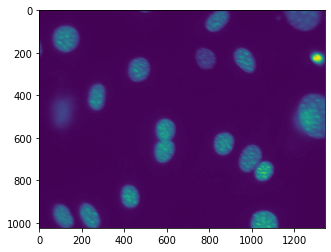

In [151]:
pylab.imshow(dna_new)
pylab.show()

You might be surprised that the image does not look at all like the one above.

This is because, by default, pylab shows images as a heatmap. You can see the more traditional grey-scale image by switching the colormap used. Instead of the default jet colourmap, we can set it to the gray one, which is the traditional greyscale representation.

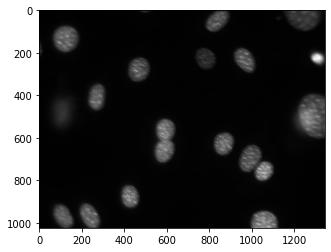

In [152]:
pylab.imshow(dna_new)
pylab.gray()
pylab.show()

In [153]:
print(dna_new.shape)
print(dna_new.dtype)
print(dna_new.max())
print(dna_new.min())

(1024, 1344)
uint8
252
0


The shape is 1024 pixels high and 1344 pixels across (recall that the convention is the matrix convention: height x width). The type is uint8, i.e., unsigned 8-bit integer. The maximum value is 252 and the minimum value is 0.

# Lets figure this out

Here’s the first idea for counting the nuclei. We are going to threshold the image and count the number of objects.




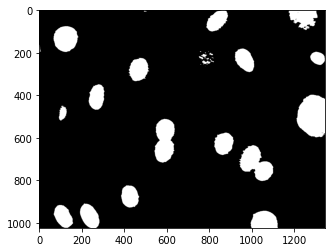

In [154]:
T = mh.thresholding.otsu(dna_new)
pylab.imshow(dna_new > T)
pylab.show()

Here, again, we are taking advantage of the fact that dna is a numpy array and using it in logical operations (dna > T). The result is a numpy array of booleans, which pylab shows as a black and white image (or red and blue if you have not previously called pylab.gray()).


This isn’t too good. The image contains many small objects. There are a couple of ways to solve this. A simple one is to smooth the image a bit using a Gaussian filter.

[[1 1 1 ... 9 9 9]
 [1 1 1 ... 9 9 9]
 [1 1 1 ... 9 9 9]
 ...
 [2 2 2 ... 1 1 1]
 [2 2 2 ... 1 1 1]
 [2 2 2 ... 1 1 1]]


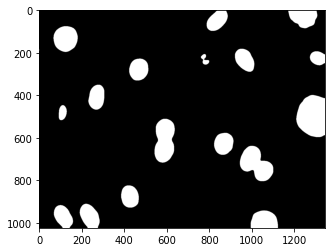

In [159]:
dnaf = mh.gaussian_filter(dna_new, 8)
dnaf1 =  dnaf.astype('uint8')
print(dnaf1)
T = mh.thresholding.otsu(dnaf1)
pylab.imshow(dnaf1 > T)
pylab.show()

The function mh.gaussian_filter takes an image and the standard deviation of the filter (in pixel units) and returns the filtered image. We are jumping from one package to the next, calling mahotas to filter the image and to compute the threshold, using numpy operations to create a thresholded images, and pylab to display it, but everyone works with numpy arrays. The result is much better.

We now have some merged nuclei (those that are touching), but overall the result looks much better. The final count is only one extra function call away:

18


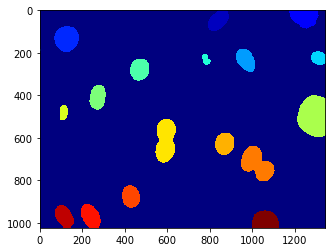

In [0]:
labeled,nr_objects = mh.label(dnaf > T)
print(nr_objects)
pylab.imshow(labeled)
pylab.jet()
pylab.show()

Is this alright?

![alt text](https://github.com/BlohmLab/NSCI801-QuantNeuro/blob/master/Figures/hardno.png?raw=1)

![alt text](https://github.com/BlohmLab/NSCI801-QuantNeuro/blob/master/Figures/Icandobetter.png?raw=1)

We now have the number of objects in the image (18), and we also displayed the labeled image. The call to pylab.jet() just resets the colourmap to jet if you still had the greyscale map active.

We can explore the labeled object. It is an integer array of exactly the same size as the image that was given to mh.label(). It’s value is the label of the object at that position, so that values range from 0 (the background) to nr_objects.


The previous result was acceptable for a first pass, but there were still nuclei glued together. Let’s try to do better.

Here is a simple, traditional, idea:

1 - smooth the image
2 - find regional maxima
3 - Use the regional maxima as seeds for watershed

## Finding the seeds

[[1.         1.         1.         ... 9.25339223 9.13803302 9.08012871]
 [1.         1.         1.         ... 9.25078765 9.13518282 9.07715502]
 [1.         1.         1.         ... 9.24549432 9.1294058  9.07113486]
 ...
 [2.         2.         2.         ... 1.         1.         1.        ]
 [2.         2.         2.         ... 1.         1.         1.        ]
 [2.         2.         2.         ... 1.         1.         1.        ]]


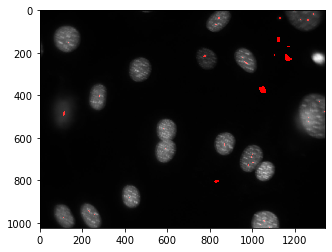

In [0]:
dnaf = mh.gaussian_filter(dna_new, 8)
print(dnaf)
dnaf_8 =  dnaf.astype('uint8')
# print(dna_new[dna_new>T])
rmax = mh.regmax(dnaf_8)
pylab.imshow(mh.overlay(dna_new, rmax))
pylab.show()

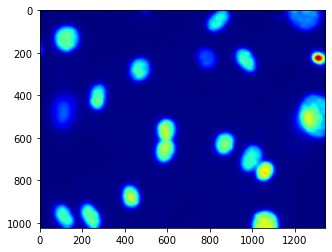

In [0]:
pylab.imshow(dnaf)
pylab.show()

After a little fiddling around, we decide to try the same idea with a thresholded_image:

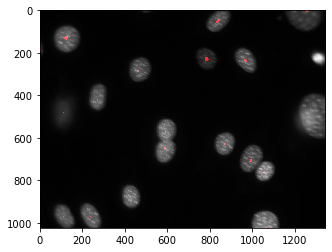

In [0]:
dnaf = mh.gaussian_filter(dna_new, 16)
dnaf_8 =  dnaf.astype('uint8')
rmax = mh.regmax(dnaf_8)
pylab.imshow(mh.overlay(dna_new, rmax))
pylab.show()

In [0]:
seeds,nr_nuclei = mh.label(rmax)
print(nr_nuclei)
np.where(seeds>0)

22


(array([   0,    0,    0, ..., 1023, 1023, 1023]),
 array([ 493,  494,  495, ..., 1062, 1063, 1064]))

Now things look much better.

# Watershed


We are going to apply watershed to the distance transform of the thresholded image:

Watershedding treats images like a set of peaks and valleys - and tries to cut them down accordingly

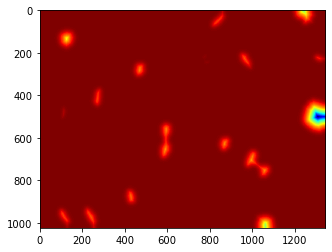

In [0]:
dnaf = mh.gaussian_filter(dna_new, 16)
# dnaf2 =  dnaf.astype('uint8')
T1 = mh.thresholding.otsu(dnaf2)
print
dist = mh.distance(dnaf2 > T1)
dist = dist.max() - dist
dist -= dist.min()
dist = dist/float(dist.ptp()) * 255
dist = dist.astype(np.uint8)
pylab.imshow(dist)
pylab.show()

After we contrast stretched the dist image, we can call mh.cwatershed to get the final result (the colours in the image come from it being displayed using the jet colourmap):



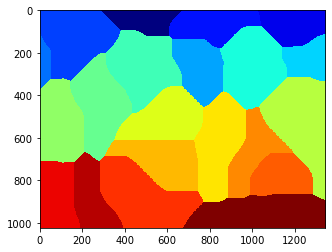

In [0]:
# dnaf = mh.gaussian_filter(dna_new, 16)
# # print(dnaf)
# dnaf_8 =  dna_new.astype('uint8')
# nuclei = mh.cwatershed(dnaf_8, seeds)
# print(nuclei)
# pylab.imshow(nuclei)
# pylab.show()

nuclei = mh.cwatershed(dist, seeds)
pylab.imshow(nuclei)
pylab.show()


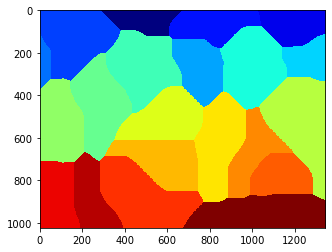

In [0]:
whole = mh.segmentation.gvoronoi(nuclei)
pylab.imshow(whole)
pylab.show()